<a href="https://colab.research.google.com/github/maricmello/Natural-Language-Processing/blob/main/BERT/05_BERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook de referência

Nome:Mariana Costa de Mello

## Instruções:


Treinar e medir a acurácia de um modelo BERT (ou variantes) para classificação binária usando o dataset do IMDB (20k/5k amostras de treino/validação).

Importante:
- Deve-se implementar o próprio laço de treinamento.
- Verificar overfit em um batch.
- Implementar o acumulo de gradiente.

Dicas:
- BERT geralmente costuma aprender bem uma tarefa com poucas épocas (de 3 a 5 épocas). Se tiver demorando mais de 5 épocas para chegar em 80% de acurácia, ajuste os hiperparametros.

- Solução para erro de memória:
  - Usar bfloat16 permite quase dobrar o batch size

Opcional:
- Pode-se usar a função trainer da biblioteca Transformers/HuggingFace para verificar se seu laço de treinamento está correto. Note que ainda assim é obrigatório implementar o laço próprio.

- Usar pytorch lightning. Para entender como o pytorch lightning funciona, veja uma implementação simplificada no notebook `06_01_Treino_Validação_MNIST_Lightning_Lite.ipynb`

# Fixando a seed

In [ ]:
!pip install gensim


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 69.3 MB/s eta 0:00:00


In [ ]:
# instalando Neptune (opcional - descomente se for usar)
# !pip install -q install transformers  neptune-client==0.9.8

In [ ]:
import random
import torch
from collections import Counter
import gensim
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
import numpy as np
from transformers import AutoTokenizer
from transformers import BertModel

import logging


In [ ]:
if torch.cuda.is_available():
   dev = "cuda:0"
   print(torch. cuda. get_device_name(dev))
else:
   dev = "cpu"
print(dev)
device = torch.device(dev)

Tesla T4
cuda:0


In [ ]:
random.seed(123)
np.random.seed(123)
torch.manual_seed(123)

## Preparando Dados

Primeiro, fazemos download do dataset:

In [ ]:
!wget -nc http://files.fast.ai/data/aclImdb.tgz
!tar -xzf aclImdb.tgz

--2026-10-22 16:12:02--  http://files.fast.ai/data/aclImdb.tgz
Resolving files.fast.ai (files.fast.ai)... 104.26.3.19, 104.26.2.19, 172.67.69.159, ...
Connecting to files.fast.ai (files.fast.ai)|104.26.3.19|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://files.fast.ai/data/aclImdb.tgz [following]
--2026-10-22 16:12:02--  https://files.fast.ai/data/aclImdb.tgz
Connecting to files.fast.ai (files.fast.ai)|104.26.3.19|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 145982645 (139M) [application/x-gtar-compressed]
Saving to: ‘aclImdb.tgz’

aclImdb.tgz         100%[===================>] 139.22M   132MB/s    in 1.1s    

2026-10-22 16:12:03 (132 MB/s) - ‘aclImdb.tgz’ saved [145982645/145982645]



## Carregando o dataset

Criaremos uma divisão de treino (20k exemplos) e validação (5k exemplos) artificialmente.

In [ ]:
import os

max_valid = 5000

def load_texts(folder):
    texts = []
    for path in os.listdir(folder):
        with open(os.path.join(folder, path)) as f:
            texts.append(f.read())
    return texts

x_train_pos = load_texts('aclImdb/train/pos')
x_train_neg = load_texts('aclImdb/train/neg')
x_test_pos = load_texts('aclImdb/test/pos')
x_test_neg = load_texts('aclImdb/test/neg')

x_train = x_train_pos + x_train_neg
x_test = x_test_pos + x_test_neg
y_train = [True] * len(x_train_pos) + [False] * len(x_train_neg)
y_test = [True] * len(x_test_pos) + [False] * len(x_test_neg)

# Embaralhamos o treino para depois fazermos a divisão treino/valid.
c = list(zip(x_train, y_train))
random.shuffle(c)
x_train, y_train = zip(*c)

x_valid = x_train[-max_valid:]
y_valid = y_train[-max_valid:]
x_train = x_train[:-max_valid]
y_train = y_train[:-max_valid]

print(len(x_train), 'amostras de treino.')
print(len(x_valid), 'amostras de desenvolvimento.')
print(len(x_test), 'amostras de teste.')

print('3 primeiras amostras treino:')
for x, y in zip(x_train[:3], y_train[:3]):
    print(y, x[:100])

print('3 últimas amostras treino:')
for x, y in zip(x_train[-3:], y_train[-3:]):
    print(y, x[:100])

print('3 primeiras amostras validação:')
for x, y in zip(x_valid[:3], y_test[:3]):
    print(y, x[:100])

print('3 últimas amostras validação:')
for x, y in zip(x_valid[-3:], y_valid[-3:]):
    print(y, x[:100])

20000 amostras de treino.
5000 amostras de desenvolvimento.
25000 amostras de teste.
3 primeiras amostras treino:
False I caught this movie at a small screening held by members of my college's gaming club. We were forewa
False This film concerns purportedly non-establishment types (aesthetically and sexually) who apparently c
True Gordon Parks, the prolific black Life magazine photographer, made a true ticking-timebomb of a movie
3 últimas amostras treino:
False This is another North East Florida production, filmed mainly in and near by to Fernandina Beach and 
True I enjoyed The Night Listener very much. It's one of the better movies of the summer.<br /><br />Robi
True WOW! What - a - movie !!!!!!!!!!! I'm not at all a fan of contemporary Italian directors. Usually I 
3 primeiras amostras validação:
True I am amazed that movies like this can still be made. I watch all kinds of movies all the time with m
True Have you heard the story about the reluctant heroes who were hired by a King 

## Carregando BERT e vizualizando as transformações

In [ ]:


tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")
encoded_input = tokenizer("Hello, I'm a single sentence!")
print(encoded_input)
print("Deconding sentence: ", tokenizer.decode(encoded_input["input_ids"]))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

{'input_ids': [101, 8667, 117, 146, 112, 182, 170, 1423, 5650, 106, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}
Deconding sentence:  [CLS] Hello, I ' m a single sentence! [SEP]


## Defindo Dataset e Dataloader

In [ ]:
# recebe os textos , tokeniza e gera os embeddings pela sentença inteira
# basedo no tutorial: https://pytorch.org/tutorials/beginner/text_sentiment_ngrams_tutorial.html

class IMDBDataset(torch.utils.data.Dataset):
    def __init__(self, sentences,
                 labels,
                 model_tokens = 'bert-base-uncased'):
        super().__init__()

        self.tokenizer = AutoTokenizer.from_pretrained(model_tokens)

        self.tokens = self.tokenizer(sentences,
                                     padding="max_length",
                                     truncation=True)["input_ids"]

        self.mask_attention = self.tokenizer(sentences,
                                             padding="max_length",
                                             truncation=True)["attention_mask"]
        self.labels = labels


    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

      #indexs, masked_indexs, label
      return torch.tensor(self.tokens[idx]).long(),\
             torch.tensor(self.mask_attention[idx]).long(),\
             torch.tensor(self.labels[idx]).long()

## Modelo de classificação de reviews

Insira seu modelo abaixo.

In [ ]:
class BertClassifier(nn.Module):
    def __init__(self, num_class, model_name='bert-base-uncased', dropout=0.1):
        super().__init__()
        self.bert = BertModel.from_pretrained(model_name)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_class)

    def forward(self, input_ids, attention_mask):
        pooled = self.bert(input_ids=input_ids, attention_mask=attention_mask).pooler_output
        return self.classifier(self.dropout(pooled))

## Laço de Treinamento
> Para implementação do accumulate grad:

> 1) Permita-se as etapas de forward e backward por n steps

> 2) Ao final do número total de steps se atualiza os otimizadores

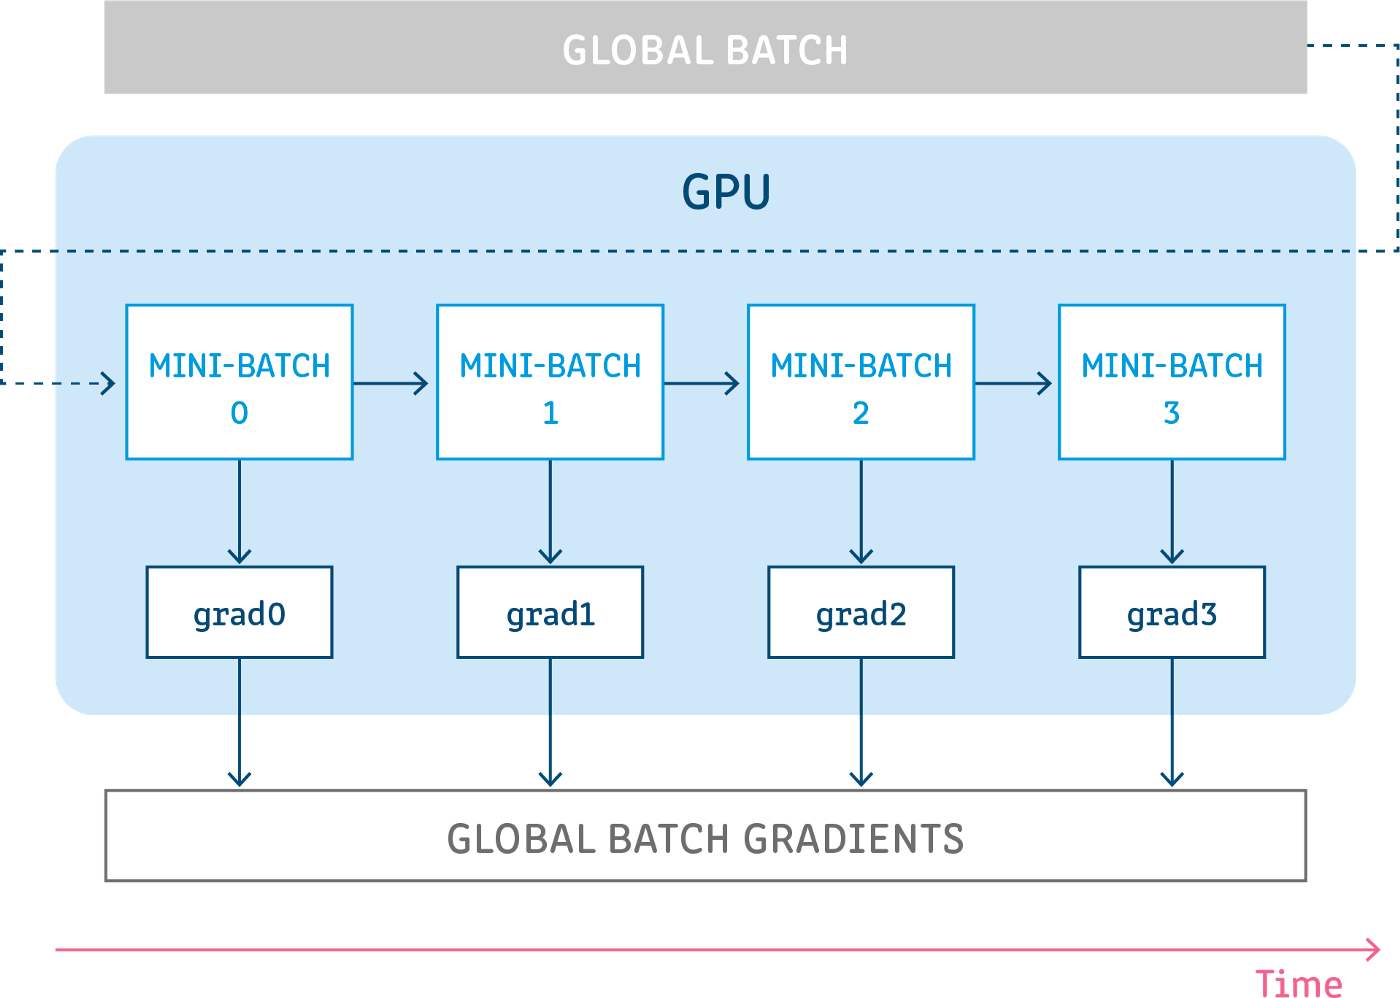

Defina abaixo seu loop de treino e validação.

In [ ]:
import math

from tqdm.auto import tqdm
from transformers import get_linear_schedule_with_warmup

use_bf16 = device.type == 'cuda' and torch.cuda.get_device_capability(device)[0] >= 8
print('Usando bfloat16:', use_bf16)


def forward_batch(model, batch):
    input_ids, attention_mask, labels = (tensor.to(device) for tensor in batch)
    with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_bf16):
        logits = model(input_ids, attention_mask)
    loss = F.cross_entropy(logits.float(), labels)
    return loss, logits, labels


def build_optimizer_and_scheduler(model, lr, loader, accum_steps, max_epochs, weight_decay=0.01, warmup_ratio=0.1):
    no_decay = ['bias', 'LayerNorm.weight']
    grouped_parameters = [
        {
            'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            'weight_decay': weight_decay,
        },
        {
            'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            'weight_decay': 0.0,
        },
    ]
    optimizer = torch.optim.AdamW(grouped_parameters, lr=lr)
    total_steps = math.ceil(len(loader) / accum_steps) * max_epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(warmup_ratio * total_steps), num_training_steps=total_steps
    )
    return optimizer, scheduler


def train_epoch(model, loader, optimizer, scheduler, accum_steps, max_grad_norm=1.0):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    num_batches = len(loader)
    remainder = num_batches % accum_steps or accum_steps
    last_group_start = num_batches - remainder

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    progress_bar = tqdm(loader, leave=False)
    for step, batch in enumerate(progress_bar):
        group_size = accum_steps if step < last_group_start else remainder

        loss, logits, labels = forward_batch(model, batch)
        (loss / group_size).backward()

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=-1) == labels).sum().item()
        total_samples += labels.size(0)

        if (step + 1) % accum_steps == 0 or (step + 1) == num_batches:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            progress_bar.set_postfix(loss=total_loss / total_samples, acc=total_correct / total_samples)

    return total_loss / total_samples, total_correct / total_samples


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for batch in tqdm(loader, leave=False):
        loss, logits, labels = forward_batch(model, batch)
        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=-1) == labels).sum().item()
        total_samples += labels.size(0)

    return total_loss / total_samples, total_correct / total_samples

Usando bfloat16: False


## Overfitting

Verifique o overfit em um batch

In [ ]:
lr = 1e-4#@param {type: "number"}
bs = 5#@param {type: "integer"}
bs_acc_step = 2
max_epochs = 7#@param {type: "integer"}
num_class = 2#@param {type: "integer"}

params = {
    'lr': lr,
    'bs': bs,
    'max_epochs': max_epochs,
    'num_class': num_class,
    'bs_acc_step':bs_acc_step
}

In [ ]:

# Datasets
train_dataset = IMDBDataset(list(x_train[:100]), list(y_train[:100]))

# Dataloaders
loader_train =  DataLoader(train_dataset, batch_size=params['bs'], shuffle=True)
loader_val = DataLoader(train_dataset, batch_size=params['bs'], shuffle=True)
loader_test = DataLoader(train_dataset, batch_size=params['bs'], shuffle=True)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
x_train_, x_train_mask, y_train_ = next(iter(DataLoader(train_dataset, batch_size=5)))
print("\nDimensões dos dados de um minibatch:", x_train_.size())
print("\nDimensões dos dados de um minibatch:", y_train_.size())


Dimensões dos dados de um minibatch: torch.Size([5, 512])

Dimensões dos dados de um minibatch: torch.Size([5])


In [ ]:
### Treino do overfitting


overfit_model = BertClassifier(params['num_class']).to(device)
overfit_optimizer = torch.optim.AdamW(overfit_model.parameters(), lr=params['lr'])
overfit_batch = (x_train_, x_train_mask, y_train_)

overfit_model.train()
for step in range(1, 51):
    overfit_optimizer.zero_grad(set_to_none=True)
    loss, logits, labels = forward_batch(overfit_model, overfit_batch)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(overfit_model.parameters(), 1.0)
    overfit_optimizer.step()

    accuracy = (logits.argmax(dim=-1) == labels).float().mean().item()
    if step % 5 == 0:
        print(f'Passo {step:02d} - loss: {loss.item():.4f} | acurácia: {accuracy:.2f}')

del overfit_model, overfit_optimizer
if device.type == 'cuda':
    torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Passo 05 - loss: 0.2600 | acurácia: 1.00
Passo 10 - loss: 0.0624 | acurácia: 1.00
Passo 15 - loss: 0.0192 | acurácia: 1.00
Passo 20 - loss: 0.0039 | acurácia: 1.00
Passo 25 - loss: 0.0014 | acurácia: 1.00
Passo 30 - loss: 0.0005 | acurácia: 1.00
Passo 35 - loss: 0.0002 | acurácia: 1.00
Passo 40 - loss: 0.0001 | acurácia: 1.00
Passo 45 - loss: 0.0001 | acurácia: 1.00
Passo 50 - loss: 0.0001 | acurácia: 1.00


## Treinamento - BERT base uncased

In [ ]:
lr = 1e-4#@param {type: "number"}
bs = 10#@param {type: "integer"}
bs_acc_step = 2
max_epochs = 5#@param {type: "integer"}
num_class = 2#@param {type: "integer"}

params = {
    'lr': lr,
    'bs': bs,
    'max_epochs': max_epochs,
    'num_class': num_class,
    'bs_acc_step':bs_acc_step
}

In [ ]:
# Datasets
train_dataset = IMDBDataset(list(x_train), list(y_train))
val_dataset = IMDBDataset(list(x_valid), list(y_valid), model_tokens = "bert-base-uncased")
test_dataset = IMDBDataset(list(x_test), list(y_test), model_tokens = "bert-base-uncased")
# Dataloaders
loader_train =  DataLoader(train_dataset, batch_size=params['bs'], shuffle=True)
loader_val = DataLoader(val_dataset, batch_size=params['bs'], shuffle=True)
loader_test = DataLoader(test_dataset, batch_size=params['bs'], shuffle=True)

In [ ]:
x_train_, x_train_mask, y_train_ = next(iter(DataLoader(train_dataset, batch_size=5)))
print("\nDimensões dos dados de um minibatch:", x_train_.size())
print("\nDimensões dos dados de um minibatch:", y_train_.size())


Dimensões dos dados de um minibatch: torch.Size([5, 512])

Dimensões dos dados de um minibatch: torch.Size([5])


In [ ]:
### Treino completo
# Esse laço demora. Para 1 época, demorou 35 min. Todas demorou ~4h

model = BertClassifier(params['num_class']).to(device)
optimizer, scheduler = build_optimizer_and_scheduler(
    model, params['lr'], loader_train, params['bs_acc_step'], params['max_epochs']
)

best_val_accuracy = 0.0
history = []

for epoch in range(1, params['max_epochs'] + 1):
    train_loss, train_accuracy = train_epoch(
        model, loader_train, optimizer, scheduler, params['bs_acc_step']
    )
    val_loss, val_accuracy = evaluate(model, loader_val)
    history.append((epoch, train_loss, train_accuracy, val_loss, val_accuracy))
    print(
        f'Época {epoch} - '
        f'train_loss: {train_loss:.4f} | train_acc: {train_accuracy:.4f} | '
        f'val_loss: {val_loss:.4f} | val_acc: {val_accuracy:.4f}'
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(model.state_dict(), 'best_bert_imdb.pt')

print(f'Melhor acurácia de validação: {best_val_accuracy:.4f}')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

Época 1 - train_loss: 0.3421 | train_acc: 0.8570 | val_loss: 0.3252 | val_acc: 0.8646


...

  0%|          | 0/500 [00:00<?, ?it/s]

Época 4 - train_loss: 0.0533 | train_acc: 0.9883 | val_loss: 0.3801 | val_acc: 0.9288


  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

Época 5 - train_loss: 0.0220 | train_acc: 0.9960 | val_loss: 0.3958 | val_acc: 0.9300
Melhor acurácia de validação: 0.9300


In [ ]:
### Avalie seu modelo em teste e retorne a acurácia

model.load_state_dict(torch.load('best_bert_imdb.pt', map_location=device))
test_loss, test_accuracy = evaluate(model, loader_test)
print(f'Teste - loss: {test_loss:.4f} | acurácia: {test_accuracy:.4f}')

  0%|          | 0/2500 [00:00<?, ?it/s]

Teste - loss: 0.4060 | acurácia: 0.9277
